[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_episodes/BA_L4_episodes.ipynb)

# BA_L4_episodes: Depeg Episodes of USDC/USDT: Duration and Depth

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Duration and peak absolute deviation of the 30 episodes in which USDC priced in USDT moved at least 15 basis points away from parity after 24 observed quiet hours, hourly, January 2022 to 23 October 2026, and the distribution of their durations. Data: EODHD hourly aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

An **episode** starts at a breach hour ($|d_t| \geq 15$ bp, $d_t$ = USDC priced in USDT, in basis points) preceded by 24 *observed* hours without a breach.
Its **duration** runs from the first to the last breach hour before 24 hours without a breach; its **peak** is the largest $|d_t|$ in between.
Left: peak against duration, both on log scales, coloured by year. Right: number of episodes by duration.

**Data:** EOD Historical Data (EODHD) hourly closing prices, January 2022 to 23 October 2026.

In [5]:
H = pd.concat({'USDC': hourly('USDC-USD.CC'), 'USDT': hourly('USDT-USD.CC'), 'DAI': hourly('DAI-USD.CC'),
               'BTC': hourly('BTC-USD.CC')}, axis=1)
H = H.reindex(pd.date_range('2022-01-01 00:00', '2026-10-23 23:00', freq='h'))   # regular hourly grid, lecture sample
dh = 1e4 * (H['USDC'] / H['USDT'] - 1)                                             # USDC priced in USDT, bp
print(f'hourly grid: {H.index[0]} to {H.index[-1]} UTC, {len(H)} hours; '
      f'hours with USDC or USDT missing: {100 * H[["USDC", "USDT"]].isna().any(axis=1).mean():.2f}%')

hourly grid: 2022-01-01 00:00:00 to 2026-10-23 23:00:00 UTC, 42168 hours; hours with USDC or USDT missing: 2.80%


In [6]:
def episodes(dd, th, quiet=24, ambiguous=False):
    """Episode starts: breach hours (|d| >= th) preceded by `quiet` hours that are all observed and below th.
    With ambiguous=True also returns the breach hours after a quiet spell that contains missing hours."""
    b = dd.abs() >= th
    valid = dd.notna()
    q = (valid & ~b).astype(float).rolling(quiet).sum().shift(1) == quiet
    start = b & valid & q
    if not ambiguous:
        return dd.index[start]
    nobreach = b.astype(float).rolling(quiet).sum().shift(1) == 0
    return dd.index[start], dd.index[b & valid & ~q & nobreach]

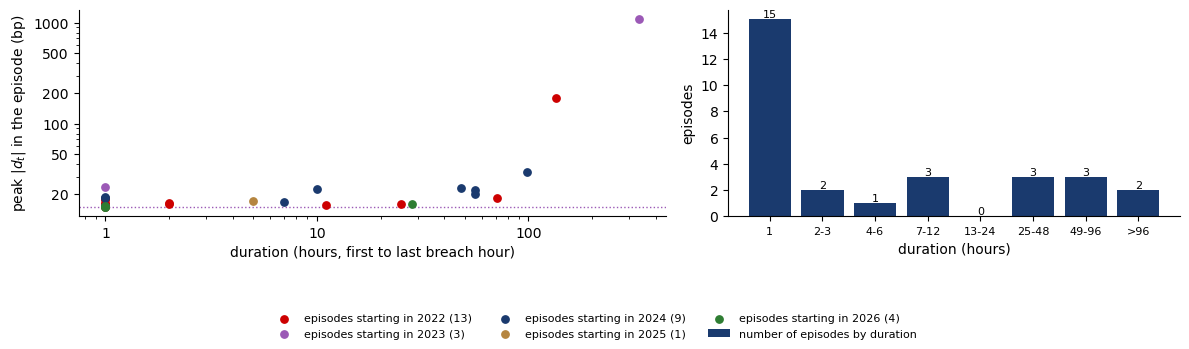

In [7]:
TH = 15
ev15 = episodes(dh, TH)
b15 = dh.abs() >= TH
rows_ = []
for t0 in ev15:
    seg, bb = dh.loc[t0:], b15.loc[t0:]
    quiet = (~bb).astype(int).rolling(24).sum().values
    k = np.argmax(quiet[24:] == 24) + 24 if (quiet[24:] == 24).any() else len(bb) - 1
    win = seg.iloc[:k - 24 + 1]                          # up to the hour before the first 24 quiet hours
    last = win[win.abs() >= TH].index[-1]
    rows_.append({'start (UTC)': t0, 'duration (h)': (last - t0) / pd.Timedelta(hours=1) + 1,
                  'breach hours': int((win.abs() >= TH).sum()), 'peak |d| (bp)': win.abs().max()})
EP = pd.DataFrame(rows_)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={'width_ratios': [1.3, 1]})
ycol = {2022: RED, 2023: ETH, 2024: BLUE, 2025: GOLD, 2026: GREEN}
for y_, c_ in ycol.items():
    m = EP['start (UTC)'].dt.year == y_
    ax[0].scatter(EP.loc[m, 'duration (h)'], EP.loc[m, 'peak |d| (bp)'], s=28, color=c_, label=f'episodes starting in {y_} ({int(m.sum())})', zorder=3)
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].axhline(TH, color=ETH, ls=':', lw=1)
ax[0].set_yticks([20, 50, 100, 200, 500, 1000])
ax[0].xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); ax[0].yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g'))
ax[0].set_xlabel('duration (hours, first to last breach hour)'); ax[0].set_ylabel(r'peak $|d_t|$ in the episode (bp)')
cnt, _ = np.histogram(EP['duration (h)'], bins=[1, 2, 4, 7, 13, 25, 49, 97, 200])
ax[1].bar(range(len(cnt)), cnt, color=BLUE, label='number of episodes by duration')
for i, c_ in enumerate(cnt):
    ax[1].text(i, c_ + 0.15, str(c_), ha='center', fontsize=8)
ax[1].set_xticks(range(len(cnt))); ax[1].set_xticklabels(['1', '2-3', '4-6', '7-12', '13-24', '25-48', '49-96', '>96'], fontsize=8)
ax[1].set_xlabel('duration (hours)'); ax[1].set_ylabel('episodes'); ax[1].yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
save(fig, 'ba_l4_episodes', 0.2, ncol=3)

## Key numbers

In [8]:
print(f'{len(EP)} episodes; median duration {EP["duration (h)"].median():.1f} h; one hour: {int((EP["duration (h)"] == 1).sum())}; '
      f'at most 6 hours: {int((EP["duration (h)"] <= 6).sum())}')
print(f'median peak {EP["peak |d| (bp)"].median():.1f} bp; peak below 25 bp: {int((EP["peak |d| (bp)"] < 25).sum())}; '
      f'Spearman correlation of duration and peak {stats.spearmanr(EP["duration (h)"], EP["peak |d| (bp)"])[0]:.2f}')
EP.round(1)

30 episodes; median duration 1.5 h; one hour: 15; at most 6 hours: 18
median peak 16.6 bp; peak below 25 bp: 27; Spearman correlation of duration and peak 0.57


,start (UTC),duration (h),breach hours,peak |d| (bp)
0,2022-02-15 14:00:00,25.0,3,15.9
1,2022-02-18 21:00:00,1.0,1,16.2
2,2022-03-02 06:00:00,1.0,1,16.2
3,2022-03-05 00:00:00,1.0,1,18.5
4,2022-03-14 22:00:00,2.0,2,16.4
5,2022-04-25 19:00:00,1.0,1,17.5
6,2022-05-23 20:00:00,1.0,1,15.0
7,2022-06-22 13:00:00,1.0,1,16.1
8,2022-06-28 03:00:00,71.0,12,18.3
9,2022-07-02 17:00:00,2.0,2,15.9


**How to read it:** half of the episodes last one hour and 27 of 30 peak below 25 bp. The two exceptions are the collapse of the FTX exchange (November 2022, 135 hours, peak 182 bp) and Silicon Valley Bank (March 2023, 335 hours, peak 1,091 bp). Longer episodes go deeper (Spearman correlation 0.57).